# Closed six-face surface around an electric dipole

A point electric dipole at the origin provides independently evaluated complex E/H samples on the six faces of an outward-oriented box. The projector then predicts fields at exterior points and is checked against the same closed-form dipole solution evaluated directly at those points. A refinement sweep shows midpoint surface-quadrature convergence. The source is enclosed by the box, so the equivalence surface is physically meaningful; targets stay outside it.

The box samples use outward unit normals and equal midpoint cell areas in m². E/H are V/m and A/m. The far-field panel shows the angular electric-field pattern; its coefficients have units V. Phase and amplitude are retained for errors, and weak-field phase is masked in plots. This analytic-source check is independent of the projection implementation, but it is not a full-wave solver validation.

In [ ]:
from pathlib import Path
import sys

cwd = Path.cwd().resolve()
repo_root = next(
    (p for p in (cwd, *cwd.parents) if (p / "core/nearfield").is_dir()), None
)
if repo_root is None:
    raise RuntimeError("Could not locate the MAPS repository root")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
if str(repo_root / "examples/nearfield") not in sys.path:
    sys.path.insert(0, str(repo_root / "examples/nearfield"))

import math
import torch
import matplotlib.pyplot as plt
from core.nearfield import (
    Surface,
    concatenate_surfaces,
    project_nearfield,
    project_farfield,
    direction_vectors_spherical,
    EPSILON_0,
    MU_0,
    C_0,
)
from notebook_utils import (
    field_components,
    field_comparison,
    error_summary,
    show_errors,
    benchmark_methods,
    show_benchmarks,
    surface_copy,
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
REAL, COMPLEX = torch.float64, torch.complex128
FREQUENCY_HZ = torch.tensor([800e6], dtype=REAL, device=DEVICE)
OMEGA = 2 * math.pi * FREQUENCY_HZ[0]
K = OMEGA * math.sqrt(EPSILON_0 * MU_0)
ETA = math.sqrt(MU_0 / EPSILON_0)
# Small SI dipole moment keeps field magnitudes readable without changing relative errors.
P_DIPOLE = torch.tensor([0.2 + 0.1j, -0.15j, 1.0], dtype=COMPLEX, device=DEVICE) * 1e-12
BOX_HALF_WIDTH_M = 0.35
print(
    f"device={DEVICE}; f={FREQUENCY_HZ.item()/1e6:.1f} MHz; λ={C_0/FREQUENCY_HZ[0].item():.3f} m; p={P_DIPOLE.detach().cpu().numpy()} C·m"
)

device=cuda; f=800.0 MHz; λ=0.375 m; p=[2.e-13+1.0e-13j 0.e+00-1.5e-13j 1.e-12+0.0e+00j] C·m


In [ ]:
def dipole_fields(points_m):
    """Evaluate outgoing electric-dipole phasors at nonzero Cartesian points.

    Args:
        points_m: Real positions with shape ``(..., 3)`` in meters.

    Returns:
        Electric and magnetic phasors with shape ``(..., 3)``, in V/m and A/m.

    Notes:
        Uses exp(-i omega t), outgoing exp(+i k r), and free-space parameters.
    """
    radius = torch.linalg.vector_norm(points_m, dim=-1)
    if bool((radius <= 0).any()):
        raise ValueError("dipole field is singular at the source origin")
    direction = points_m / radius[..., None]
    direction_c = direction.to(COMPLEX)
    projection = (direction_c * P_DIPOLE).sum(dim=-1, keepdim=True)
    green = torch.exp(1j * K * radius) / (4 * math.pi)
    electric = (
        green[..., None]
        / EPSILON_0
        * (
            K.square() / radius[..., None] * (P_DIPOLE - direction_c * projection)
            + (1 / radius**3 - 1j * K / radius**2)[..., None]
            * (3 * direction_c * projection - P_DIPOLE)
        )
    )
    magnetic = (OMEGA * (K / radius + 1j / radius.square()) * green)[
        ..., None
    ] * torch.linalg.cross(direction_c, P_DIPOLE.expand_as(direction_c), dim=-1)
    return electric, magnetic


def make_box(cells_per_side):
    """Sample all six closed-box faces at cell centers with outward normals."""
    spacing = 2 * BOX_HALF_WIDTH_M / cells_per_side
    q = (
        torch.arange(cells_per_side, dtype=REAL, device=DEVICE) + 0.5
    ) * spacing - BOX_HALF_WIDTH_M
    a, b = torch.meshgrid(q, q, indexing="ij")
    faces = []
    # Each pair lists face axis/sign; transverse coordinates fill each midpoint grid.
    for axis in range(3):
        transverse = [idx for idx in range(3) if idx != axis]
        for sign in (-1.0, 1.0):
            positions = torch.zeros(
                (cells_per_side, cells_per_side, 3), dtype=REAL, device=DEVICE
            )
            positions[..., axis] = sign * BOX_HALF_WIDTH_M
            positions[..., transverse[0]] = a
            positions[..., transverse[1]] = b
            normals = torch.zeros_like(positions)
            normals[..., axis] = sign
            e, h = dipole_fields(positions.reshape(-1, 3))
            faces.append(
                Surface(
                    positions.reshape(-1, 3),
                    normals.reshape(-1, 3),
                    torch.full(
                        (cells_per_side * cells_per_side,),
                        spacing**2,
                        dtype=REAL,
                        device=DEVICE,
                    ),
                    e.unsqueeze(0),
                    h.unsqueeze(0),
                    FREQUENCY_HZ,
                )
            )
    return concatenate_surfaces(faces)


# Explicit and auditable outward normals on all six faces.
base_n = 13 if DEVICE.type == "cuda" else 9
surface = make_box(base_n)
print(
    f"faces=6; samples/face={base_n**2}; total samples={surface.positions_m.shape[0]}; cell area={(2*BOX_HALF_WIDTH_M/base_n)**2:.6g} m²"
)

faces=6; samples/face=169; total samples=1014; cell area=0.00289941 m²


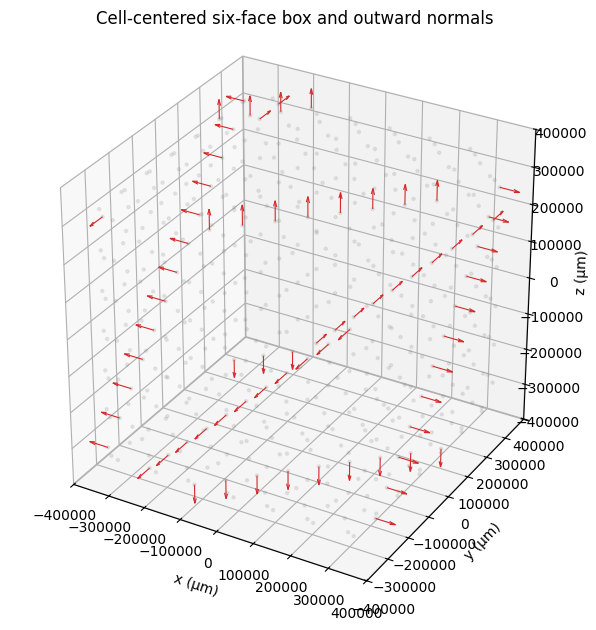

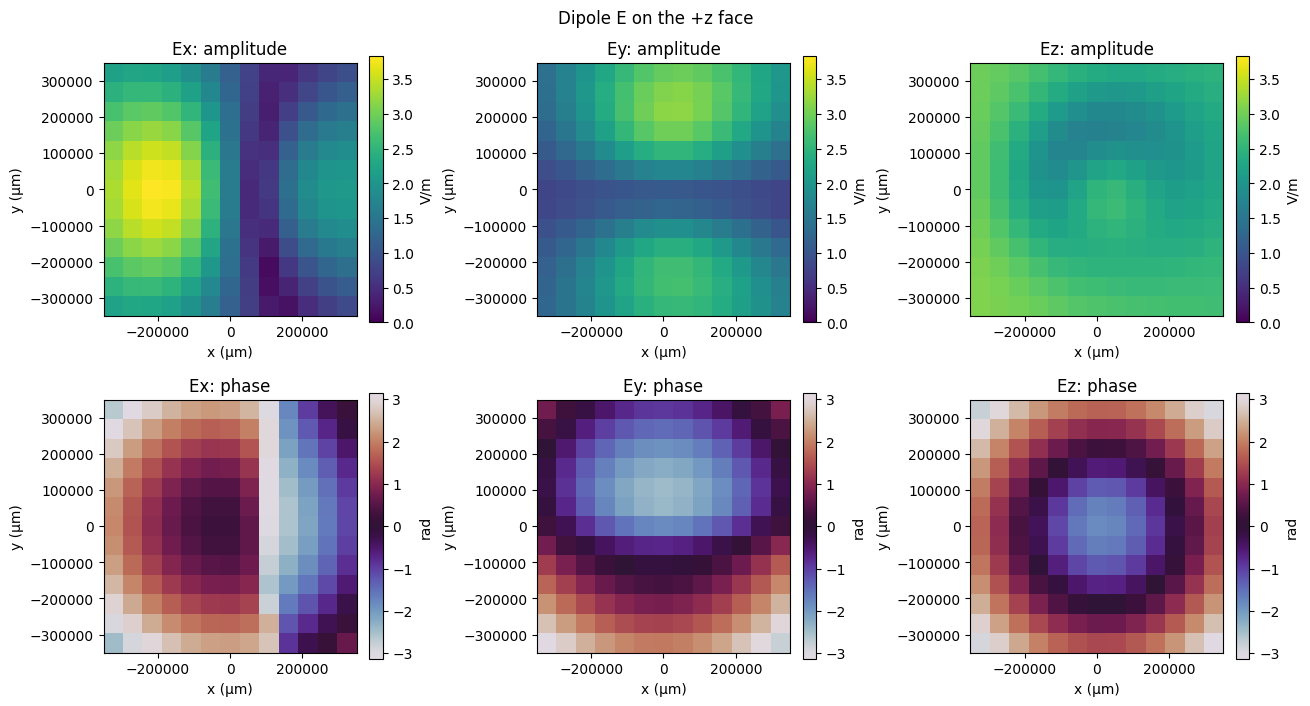

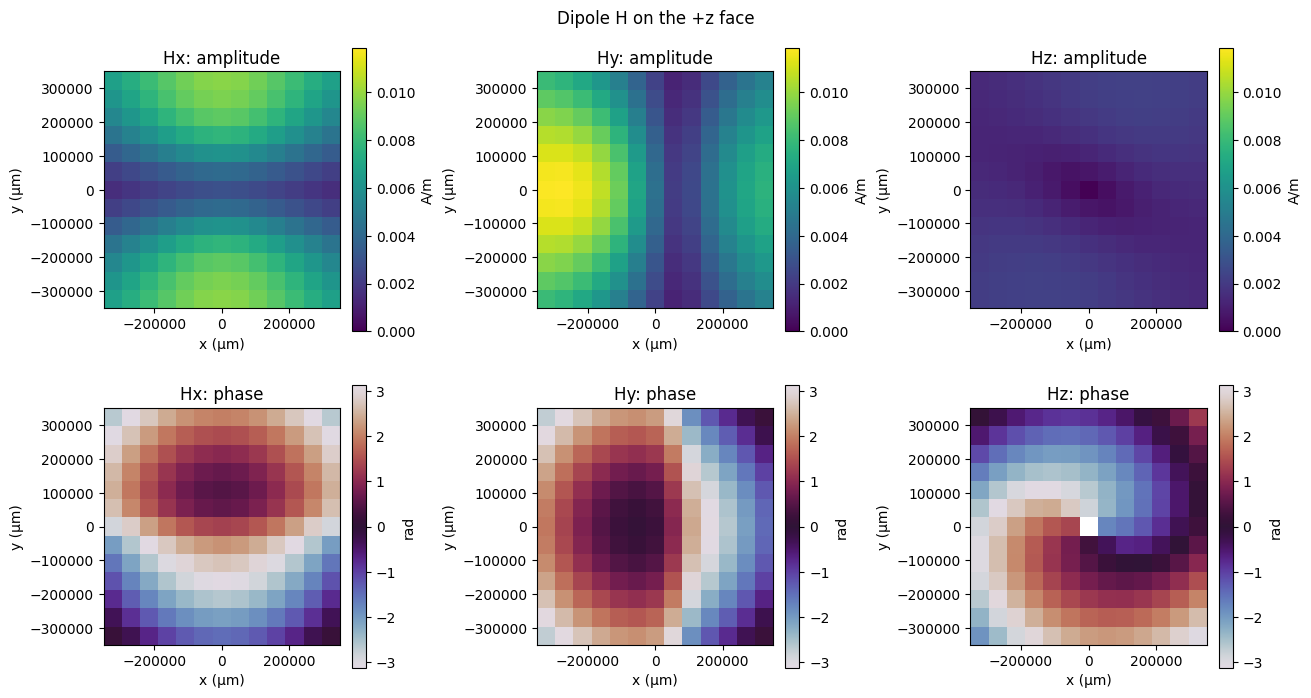

In [ ]:
# Render the sampled surface with its outward normals, plus field maps over all six patches.
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

pos_um = surface.positions_m.detach().cpu().numpy() * 1e6
normals = surface.normals.detach().cpu().numpy()
fig = plt.figure(figsize=(7, 6), constrained_layout=True)
ax = fig.add_subplot(111, projection="3d")
stride = max(1, base_n // 5)
ax.scatter(
    pos_um[::stride, 0],
    pos_um[::stride, 1],
    pos_um[::stride, 2],
    s=5,
    alpha=0.15,
    color="gray",
)
selected = torch.arange(
    0, surface.positions_m.shape[0], max(1, base_n**2 // 12), device=DEVICE
)
ps = surface.positions_m[selected].detach().cpu().numpy() * 1e6
ns = surface.normals[selected].detach().cpu().numpy()
ax.quiver(
    ps[:, 0],
    ps[:, 1],
    ps[:, 2],
    ns[:, 0],
    ns[:, 1],
    ns[:, 2],
    length=0.15 * BOX_HALF_WIDTH_M * 1e6,
    normalize=True,
    color="tab:red",
    linewidth=0.8,
)
ax.set(
    xlabel="x (µm)",
    ylabel="y (µm)",
    zlabel="z (µm)",
    title="Cell-centered six-face box and outward normals",
)
ax.set_box_aspect((1, 1, 1))
plt.show()

# Component maps are shown face-by-face for a representative +z panel.
plus_z = surface.normals[:, 2] > 0.5
face_positions = surface.positions_m[plus_z]
face_axis = torch.unique(face_positions[:, 0]).sort().values
# Sort samples into the construction mesh ordering from their y/x coordinates.
face_indices = torch.nonzero(plus_z, as_tuple=False).squeeze(-1)
spacing = 2 * BOX_HALF_WIDTH_M / base_n
face_xi = torch.round(
    (surface.positions_m[face_indices, 0] + BOX_HALF_WIDTH_M) / spacing - 0.5
).to(torch.long)
face_yi = torch.round(
    (surface.positions_m[face_indices, 1] + BOX_HALF_WIDTH_M) / spacing - 0.5
).to(torch.long)
face_order = torch.argsort(face_yi * base_n + face_xi)
face_indices = face_indices[face_order]
face_e = surface.electric_fields[0, face_indices].reshape(base_n, base_n, 3)
face_h = surface.magnetic_fields[0, face_indices].reshape(base_n, base_n, 3)
face_axis_um = (
    (torch.arange(base_n, dtype=REAL, device=DEVICE) + 0.5)
    * (2 * BOX_HALF_WIDTH_M / base_n)
    - BOX_HALF_WIDTH_M
).cpu().numpy() * 1e6
_ = field_components(
    face_e,
    face_axis_um,
    face_axis_um,
    title="Dipole E on the +z face",
    quantity="E",
    units="V/m",
)
_ = field_components(
    face_h,
    face_axis_um,
    face_axis_um,
    title="Dipole H on the +z face",
    quantity="H",
    units="A/m",
)

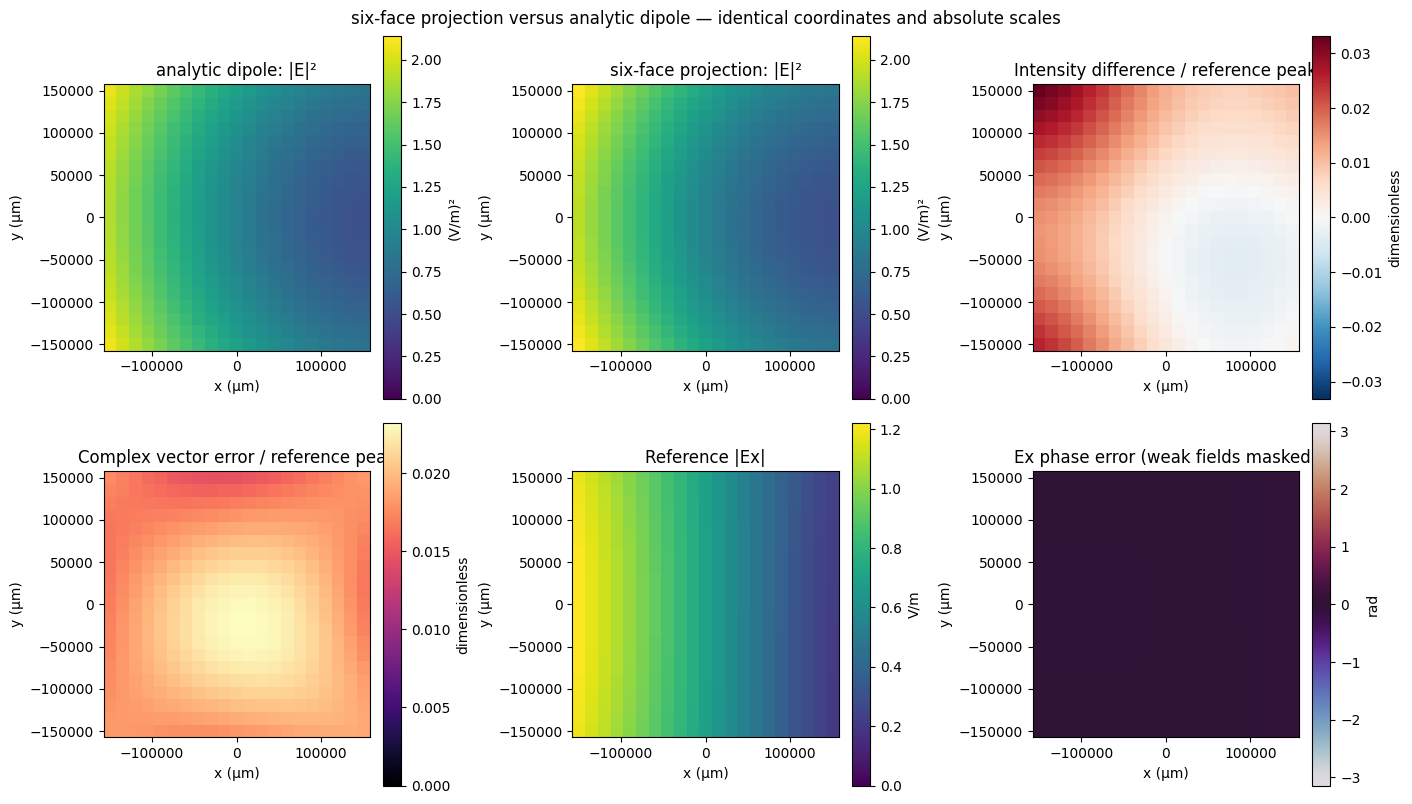

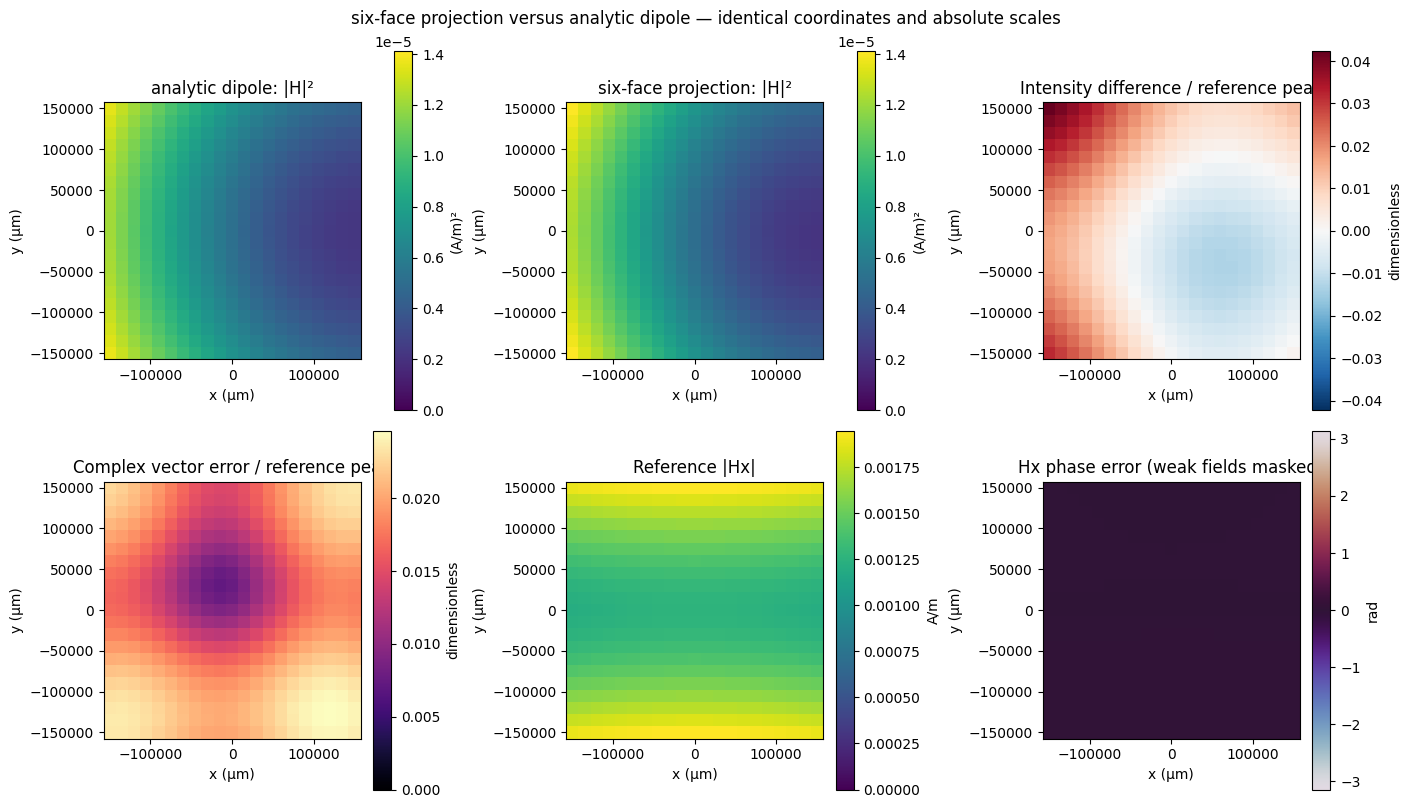

label,relative_complex_l2,relative_amplitude_l2,phase_rms_rad,strong_relative_l2,weak_absolute_over_peak,strong_count,weak_count
"exterior E, z=0.8 m",0.02628,0.017657,0.024274,0.02628,N/A,441,0
"exterior H, z=0.8 m",0.026441,0.018379,0.024765,0.026441,N/A,441,0


label,relative_complex_l2,relative_amplitude_l2,phase_rms_rad,strong_relative_l2,weak_absolute_over_peak,strong_count,weak_count
dipole far E coefficient,0.0093293,0.0068608,0.0109,0.0093293,N/A,101,0
dipole far H coefficient,0.0093293,0.0068608,0.008262,0.0093293,N/A,101,0


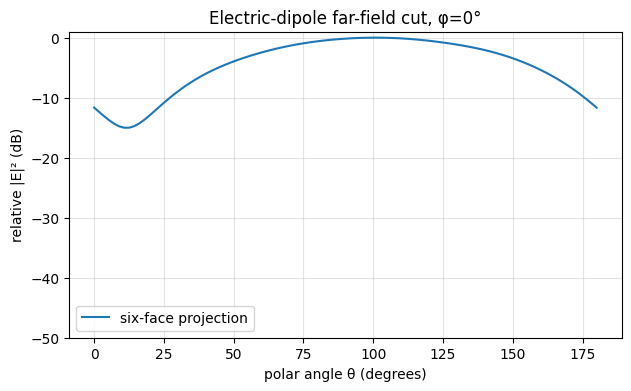

In [ ]:
# Exterior Cartesian target plane, compared against an independent direct analytic evaluation.
target_n = 21 if DEVICE.type == "cuda" else 15
plane_axis_m = torch.linspace(-0.15, 0.15, target_n, dtype=REAL, device=DEVICE)
y_t, x_t = torch.meshgrid(plane_axis_m, plane_axis_m, indexing="ij")
target_z_m = 0.8
points = torch.stack((x_t, y_t, torch.full_like(x_t, target_z_m)), dim=-1).reshape(
    -1, 3
)
E_projected, H_projected = project_nearfield(
    surface, points, source_chunk_size=512, observation_chunk_size=128
)
E_analytic, H_analytic = dipole_fields(points)
# Add the frequency axis to the independent analytical result.
E_analytic, H_analytic = E_analytic.unsqueeze(0), H_analytic.unsqueeze(0)
_ = field_comparison(
    E_analytic.reshape(target_n, target_n, 3),
    E_projected.reshape(target_n, target_n, 3),
    plane_axis_m.cpu().numpy() * 1e6,
    plane_axis_m.cpu().numpy() * 1e6,
    names=("analytic dipole", "six-face projection"),
    quantity="E",
    units="V/m",
)
_ = field_comparison(
    H_analytic.reshape(target_n, target_n, 3),
    H_projected.reshape(target_n, target_n, 3),
    plane_axis_m.cpu().numpy() * 1e6,
    plane_axis_m.cpu().numpy() * 1e6,
    names=("analytic dipole", "six-face projection"),
    quantity="H",
    units="A/m",
)
show_errors(
    [
        error_summary(E_analytic, E_projected, label=f"exterior E, z={target_z_m:g} m"),
        error_summary(H_analytic, H_projected, label=f"exterior H, z={target_z_m:g} m"),
    ]
)

# Far-field dipole pattern: compare the projected coefficient to the analytic radiation coefficient.
theta = torch.linspace(
    0.0, math.pi, 101 if DEVICE.type == "cuda" else 61, dtype=REAL, device=DEVICE
)
phi = torch.zeros_like(theta)
directions = direction_vectors_spherical(theta, phi)
E_far, H_far = project_farfield(surface, directions)
dot = (directions.to(COMPLEX) * P_DIPOLE).sum(-1, keepdim=True)
E_far_analytic = (K.square() * torch.exp(1j * K * 0) / (4 * math.pi * EPSILON_0)) * (
    P_DIPOLE - directions.to(COMPLEX) * dot
)
H_far_analytic = (
    torch.linalg.cross(directions.to(COMPLEX), E_far_analytic, dim=-1) / ETA
)
show_errors(
    [
        error_summary(E_far_analytic, E_far, label="dipole far E coefficient"),
        error_summary(H_far_analytic, H_far, label="dipole far H coefficient"),
    ]
)
fig, ax = plt.subplots(figsize=(6.2, 3.8), constrained_layout=True)
cut = 10 * torch.log10(
    (
        E_far.abs().square().sum(-1)[0]
        / E_far.abs().square().sum(-1).max().clamp_min(torch.finfo(REAL).tiny)
    ).clamp_min(1e-12)
)
ax.plot(torch.rad2deg(theta).cpu(), cut.detach().cpu(), label="six-face projection")
ax.set(
    xlabel="polar angle θ (degrees)",
    ylabel="relative |E|² (dB)",
    title="Electric-dipole far-field cut, φ=0°",
    ylim=(-50, 1),
)
ax.grid(True, alpha=0.35)
ax.legend()
plt.show()

label,relative_complex_l2,relative_amplitude_l2,phase_rms_rad,strong_relative_l2,weak_absolute_over_peak,strong_count,weak_count
"E, 7 per edge",0.10221,0.071185,0.09471,0.10221,N/A,441,0
"H, 7 per edge",0.10304,0.071364,0.10646,0.10304,N/A,441,0
"E, 11 per edge",0.037385,0.025261,0.034478,0.037385,N/A,441,0
"H, 11 per edge",0.037626,0.026148,0.035723,0.037626,N/A,441,0
"E, 17 per edge",0.015082,0.010074,0.01396,0.015082,N/A,441,0
"H, 17 per edge",0.015169,0.010546,0.014019,0.015169,N/A,441,0
"E, 25 per edge",0.0068774,0.0045735,0.0063782,0.0068774,N/A,441,0
"H, 25 per edge",0.0069151,0.0048076,0.0063296,0.0069151,N/A,441,0


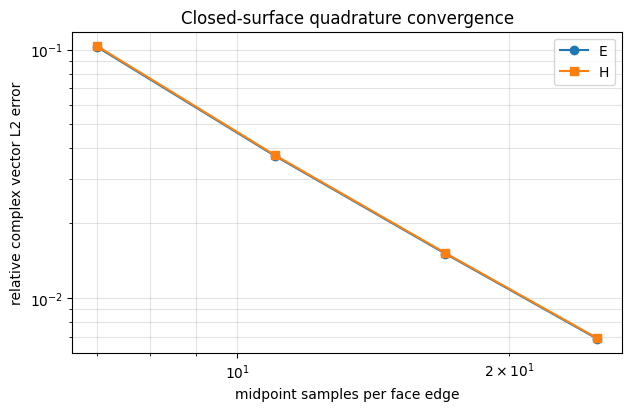

method,device,dtype,output_shape,first_forward_ms,warm_forward_ms,first_gradient_forward_ms,first_backward_ms,warm_backward_ms,warm_forward_backward_ms,peak_allocated_mib,peak_increment_mib,warmups,repeats
exact Torch near,cuda,torch.complex128,"(1, 441, 3)",35.057,35.037,786.1,33.09,23.559,59.357,44.478,35.32,1,3


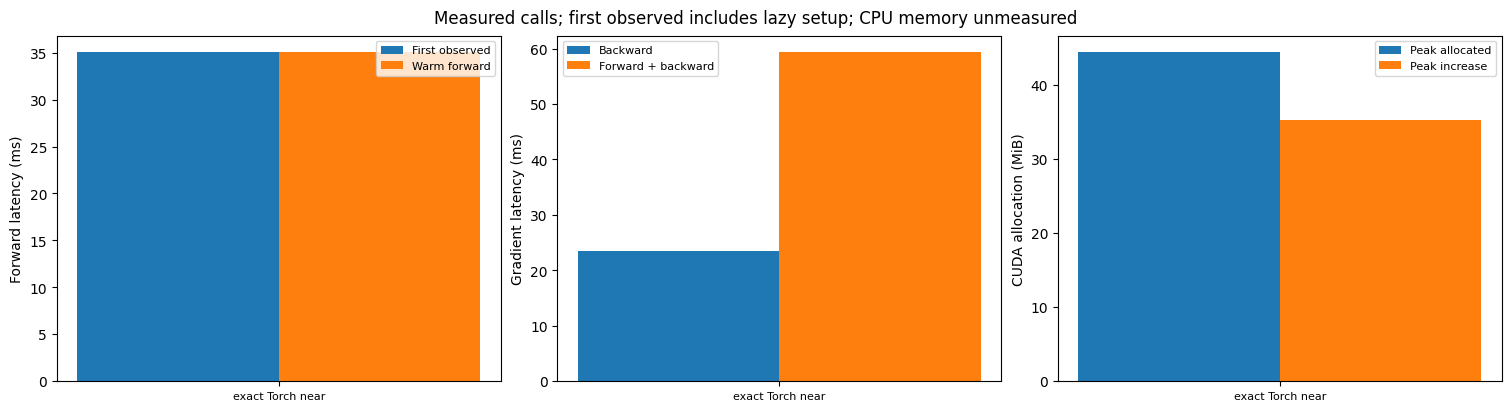

In [ ]:
# Midpoint quadrature refinement: retain physical complex amplitudes and report vector errors.
resolution_list = [7, 11, 17, 25] if DEVICE.type == "cuda" else [5, 7, 9, 13]
convergence = []
for n in resolution_list:
    candidate = make_box(n)
    ep, hp = project_nearfield(
        candidate, points, source_chunk_size=512, observation_chunk_size=128
    )
    convergence.append(
        (
            n,
            error_summary(E_analytic, ep, label=f"E, {n} per edge"),
            error_summary(H_analytic, hp, label=f"H, {n} per edge"),
            float(
                (E_analytic - ep).norm().item() / max(E_analytic.norm().item(), 1e-300)
            ),
            float(
                (H_analytic - hp).norm().item() / max(H_analytic.norm().item(), 1e-300)
            ),
        )
    )
show_errors(
    [
        record
        for _, e_record, h_record, _, _ in convergence
        for record in (e_record, h_record)
    ]
)
fig, ax = plt.subplots(figsize=(6.2, 4.0), constrained_layout=True)
ax.loglog(
    [n for n, _, _, _, _ in convergence],
    [e_error for _, _, _, e_error, _ in convergence],
    "o-",
    label="E",
)
ax.loglog(
    [n for n, _, _, _, _ in convergence],
    [h_error for _, _, _, _, h_error in convergence],
    "s-",
    label="H",
)
ax.set(
    xlabel="midpoint samples per face edge",
    ylabel="relative complex vector L2 error",
    title="Closed-surface quadrature convergence",
)
ax.grid(True, which="both", alpha=0.35)
ax.legend()
plt.show()

# Runtime/memory report for exact finite-distance projection, including field backward.
bench_surface = surface_copy(surface, requires_grad=True)
bench_methods = {
    "exact Torch near": lambda: project_nearfield(
        bench_surface, points, source_chunk_size=512, observation_chunk_size=128
    )
}
benchmarks = benchmark_methods(
    bench_methods,
    device=DEVICE,
    backward_inputs=(bench_surface.electric_fields, bench_surface.magnetic_fields),
)
show_benchmarks(benchmarks)